1.  Importing the liabraries

In [1]:
import pandas as pd

2. Importing the Dataset

In [2]:
data = pd.read_csv('heart.csv')
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


3. Taking Care of Missing Values

In [3]:
data.isnull()
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

4. Taking care of Duplicate Values

In [4]:
data_dup = data.duplicated().any()
data_dup

np.True_

In [5]:
data = data.drop_duplicates()

In [6]:
data_dup = data.duplicated().any()
data_dup

np.False_

5. Data Processing

In [7]:
cate_val = [ ]
cont_val = [ ]

for column in data.columns:
    if data[column].nunique() <= 10:
        cate_val.append(column)
    else:
        cont_val.append(column)

In [8]:
cate_val

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [9]:
cont_val

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

6. Encoding Categorial Data

In [10]:
cate_val

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [11]:
data['cp'].unique()

array([0, 1, 2, 3])

In [12]:
cate_val.remove('sex')
cate_val.remove('target')   
data = pd.get_dummies(data,columns=cate_val,drop_first=True)

In [13]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,1,125,212,168,1.0,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,53,1,140,203,155,3.1,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,70,1,145,174,125,2.6,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,61,1,148,203,161,0.0,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,62,0,138,294,106,1.9,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


7. Feature Scaling

In [14]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,1,125,212,168,1.0,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,53,1,140,203,155,3.1,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,70,1,145,174,125,2.6,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,61,1,148,203,161,0.0,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,62,0,138,294,106,1.9,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


In [15]:
from sklearn.preprocessing import StandardScaler

In [16]:
st = StandardScaler()
data[cont_val] = st.fit_transform(data[cont_val])

In [17]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,-0.267966,1,-0.376556,-0.667728,0.806035,-0.037124,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,-0.157260,1,0.478910,-0.841918,0.237495,1.773958,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,1.724733,1,0.764066,-1.403197,-1.074521,1.342748,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,0.728383,1,0.935159,-0.841918,0.499898,-0.899544,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,0.839089,0,0.364848,0.919336,-1.905464,0.739054,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


8. Spliting the Dataset into the training set and test set

In [18]:
X = data.drop('target',axis=1)

In [19]:
X

,age,sex,trestbps,chol,thalach,oldpeak,cp_1,cp_2,cp_3,fbs_1,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,-0.267966,1,-0.376556,-0.667728,0.806035,-0.037124,False,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,-0.157260,1,0.478910,-0.841918,0.237495,1.773958,False,False,False,True,...,True,False,False,False,False,False,False,False,False,True
2,1.724733,1,0.764066,-1.403197,-1.074521,1.342748,False,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,0.728383,1,0.935159,-0.841918,0.499898,-0.899544,False,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,0.839089,0,0.364848,0.919336,-1.905464,0.739054,False,False,False,True,...,False,True,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,1.503322,0,-0.661712,-0.687083,-1.511859,0.394086,False,True,False,False,...,False,True,False,False,False,False,False,False,True,False
733,-1.153610,0,-1.346085,-2.041893,1.112172,-0.382092,False,True,False,False,...,False,True,False,False,False,False,False,False,True,False
739,-0.267966,1,-0.205463,0.164513,0.499898,-0.899544,False,False,False,False,...,True,False,True,True,False,False,False,False,False,True
843,0.506972,1,1.619532,0.512893,-1.074521,-0.899544,False,False,True,False,...,False,False,True,False,False,False,False,False,True,False


In [20]:
y = data['target']

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

9. Logistic Regression

In [23]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,-0.267966,1,-0.376556,-0.667728,0.806035,-0.037124,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,-0.157260,1,0.478910,-0.841918,0.237495,1.773958,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,1.724733,1,0.764066,-1.403197,-1.074521,1.342748,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,0.728383,1,0.935159,-0.841918,0.499898,-0.899544,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,0.839089,0,0.364848,0.919336,-1.905464,0.739054,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


In [24]:
from  sklearn.linear_model import LogisticRegression

In [25]:
log = LogisticRegression()
log.fit(X_train,y_train)

LogisticRegression()

In [26]:
y_pred1 = log.predict(X_test)

In [27]:
from sklearn.metrics import accuracy_score

In [28]:
accuracy_score(y_test,y_pred1)

0.7868852459016393

10. SVC

In [29]:
from sklearn import svm

In [30]:
svm = svm.SVC()

In [31]:
svm.fit(X_train,y_train)

SVC()

In [32]:
y_pred2 = svm.predict(X_test)

In [33]:
accuracy_score(y_test,y_pred2)

0.8032786885245902

11. KNeighbours Classifier

In [34]:
from sklearn.neighbors import KNeighborsClassifier

In [35]:
knn = KNeighborsClassifier()

In [36]:
knn.fit(X_train,y_train)

KNeighborsClassifier()

In [37]:
y_pred3 = knn.predict(X_test)

In [38]:
accuracy_score(y_test,y_pred3)

0.7377049180327869

In [39]:
score = [ ]

for k in range(1,40):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    y_pred = knn.predict(X_test)
    score.append(accuracy_score(y_test,y_pred))

In [40]:
score

[0.7213114754098361,
 0.8032786885245902,
 0.7049180327868853,
 0.7049180327868853,
 0.7377049180327869,
 0.8032786885245902,
 0.7868852459016393,
 0.8032786885245902,
 0.7704918032786885,
 0.7540983606557377,
 0.7704918032786885,
 0.7540983606557377,
 0.7377049180327869,
 0.7377049180327869,
 0.7540983606557377,
 0.7704918032786885,
 0.7540983606557377,
 0.7540983606557377,
 0.7377049180327869,
 0.7540983606557377,
 0.7377049180327869,
 0.7213114754098361,
 0.7377049180327869,
 0.7377049180327869,
 0.7213114754098361,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869,
 0.7377049180327869]

In [41]:
knn = KNeighborsClassifier(n_neighbors=2)
knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.8032786885245902

Non Linear ML Algorithmns


In [42]:
data = pd.read_csv('heart.csv')
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [43]:
data = data.drop_duplicates()

In [44]:
data.shape

(302, 14)

In [45]:
X = data.drop('target',axis=1)
y = data['target']

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

12. Decision Tree Classifier

In [47]:
from sklearn.tree import DecisionTreeClassifier

In [48]:
dt = DecisionTreeClassifier()

In [49]:
dt.fit(X_train,y_train)

DecisionTreeClassifier()

In [50]:
y_pred4 = dt.predict(X_test)

In [51]:
accuracy_score(y_test,y_pred4)

0.7540983606557377

13. Random Forest Classifier

In [52]:
from sklearn.ensemble import RandomForestClassifier

In [53]:
rf = RandomForestClassifier()

In [54]:
rf.fit(X_train,y_train)

RandomForestClassifier()

In [55]:
y_pred5 = rf.predict(X_test)

In [56]:
accuracy_score(y_test,y_pred5)

0.819672131147541

14. Gradient Boosting Classifier

In [57]:
from sklearn.ensemble import GradientBoostingClassifier

In [58]:
gbc = GradientBoostingClassifier()

In [59]:
gbc.fit(X_train,y_train)

GradientBoostingClassifier()

In [60]:
y_pred6 = gbc.predict(X_test)

In [61]:
accuracy_score(y_test,y_pred6)

0.8032786885245902

In [62]:
final_data = pd.DataFrame({'Models': ['LR', 'SVM', 'KNN', 'DT', 'RF', 'GB'],
                                                    'ACC': [accuracy_score(y_test,y_pred1),
                                                                accuracy_score(y_test,y_pred2),
                                                                accuracy_score(y_test,y_pred3),
                                                                accuracy_score(y_test,y_pred4),
                                                                accuracy_score(y_test,y_pred5),
                                                                accuracy_score(y_test,y_pred6),] })

In [63]:
final_data

,Models,ACC
0,LR,0.786885
1,SVM,0.803279
2,KNN,0.737705
3,DT,0.754098
4,RF,0.819672
5,GB,0.803279


In [64]:
import seaborn as sns

<Axes: xlabel='Models', ylabel='ACC'>

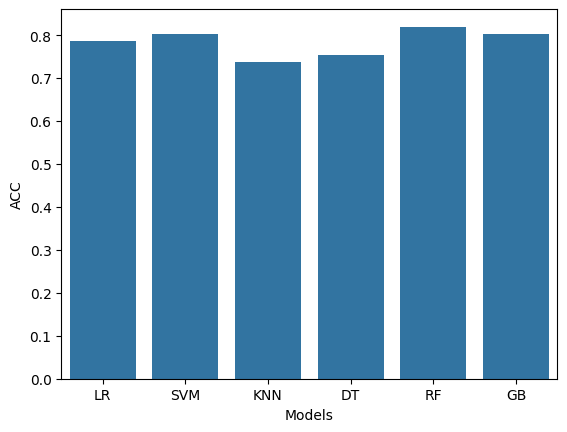

In [65]:
sns.barplot(data=final_data, x='Models', y='ACC')

In [66]:
X = data.drop('target',axis=1)
y = data['target']

In [67]:
X.shape

(302, 13)

In [68]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X,y)

RandomForestClassifier()

15. Prediction on New Data

In [69]:
import pandas as pd

In [70]:
new_data = pd.DataFrame({
        'age' : 52,
        'sex': 1,
        'cp': 0,
        'trestbps': 125,
        'chol':22,
        'fbs':0,
        'restecg':1,
        'thalach':168,
        'exang':0,
        'oldpeak':1.0,
        'slope':2,
        'ca':2,
        'thal':3,
},index=[0])

In [71]:
new_data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,22,0,1,168,0,1.0,2,2,3


In [72]:
p = rf.predict(new_data)
if p[0] == 0:
    print("No Disease")
else:
    print("Disease")

No Disease


16. save model using joblib

In [73]:
import joblib

In [74]:
joblib.dump(rf,'model_joblib_heart')

['model_joblib_heart']

In [75]:
model = joblib.load('model_joblib_heart')

In [76]:
model.predict(new_data)

array([0])

GUI

In [77]:
from tkinter import *
import joblib

In [78]:
def show_entry_fields():
        p1 = int(e1.get())
        p2 = int(e2.get())
        p3 = int(e3.get())
        p4 = int(e4.get())
        p5 = int(e5.get())
        p6 = int(e6.get())
        p7 = int(e7.get())
        p8 = int(e8.get())
        p9 = int(e9.get())
        p10 = float(e10.get())
        p11 = int(e11.get())
        p12 = int(e12.get())
        p13 = int(e13.get())
        model = joblib.load('model_joblib_heart')
        data = pd.DataFrame([[p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,p13]],
                    columns=['age','sex','cp','trestbps','chol','fbs',
                             'restecg','thalach','exang','oldpeak',
                             'slope','ca','thal'])

        result = model.predict(data)
        # result = model.predict([[p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,p13]])

        if result[0] == 0:
            Label(master,text="No Heart Diseases").grid(row=31)
        else:
            Label(master, text='Possibility of Heart Diseases').grid(row=31)

master = Tk()
master.title("Heart Disease Prediction System")

label = Label(master, text="Heart Disease Prediction System",bg="black",fg='white'). grid(row=0,columnspan=2)

Label(master, text="Enter your Age").grid(row=1)
Label(master, text="Male or Female [1/0]").grid(row=2)
Label(master, text="Enter value of CP").grid(row=3)
Label(master, text="Enter value of trestbps").grid(row=4)
Label(master, text="Enter value of chol").grid(row=5)
Label(master, text="Enter value of fbs").grid(row=6)
Label(master, text="Enter value of restecg").grid(row=7)
Label(master, text="Enter value of thalach").grid(row=8)
Label(master, text="Enter value of exang").grid(row=9)
Label(master, text="Enter value of oldpeak").grid(row=10)
Label(master, text="Enter value of slope").grid(row=11)
Label(master, text="Enter value of ca").grid(row=13)
Label(master, text="Enter value of thal").grid(row=12)

e1 = Entry(master)
e2 = Entry(master)
e3 = Entry(master)
e4 = Entry(master)
e5 = Entry(master)
e6 = Entry(master)
e7 = Entry(master)
e8 = Entry(master)
e9 = Entry(master)
e10 = Entry(master)
e11 = Entry(master)
e12 = Entry(master)
e13 = Entry(master)

e1.grid(row=1, column=1)
e2.grid(row=2, column=1)
e3.grid(row=3, column=1)
e4.grid(row=4, column=1)
e5.grid(row=5, column=1)
e6.grid(row=6, column=1)
e7.grid(row=7, column=1)
e8.grid(row=8, column=1)
e9.grid(row=9, column=1)
e10.grid(row=10, column=1)
e11.grid(row=11, column=1)
e12.grid(row=12, column=1)
e13.grid(row=13, column=1)

Button(master, text='Predict', command = show_entry_fields).grid()
mainloop()
